<a href="https://www.kaggle.com/code/najeebullah160/phase4-explainability-llm-narration?scriptVersionId=372613593" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

**Phase 4 — Explainability & LLM Narration**

Five explanation layers over the trained GraphIDS detector:

1. **Exact per-dim reconstruction error** in GNN embedding space, where z = [src-context 48 | flow 45 | dst-context 48]
2. **Integrated Gradients** (Captum) — attribution of each edge's anomaly score to its 45 flow features
3. **Aggregate forensics** — why Exploits are missed, what drives false positives
4. **Case studies** — flagship TP / FN / FP edges
5. **Groq SOC alerts** + automated faithfulness check


**Needs:** GPU T4 · Inputs: Phase 2 output AND Phase 3 output · Runtime ≈ 20–30 min

In [1]:
# === CELL 2: SETUP + ARTIFACT AUTO-LOCATE ===
import subprocess, sys, importlib
def ensure(pkg, pip_name=None):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip_name or pkg], check=False)
ensure('captum'); ensure('pyarrow'); ensure('sklearn', 'scikit-learn'); ensure('joblib')

import os, json, glob, shutil, random, time, re
import numpy as np, pandas as pd, torch
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score
from captum.attr import IntegratedGradients

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if device.type == 'cuda': torch.cuda.manual_seed_all(SEED)
os.makedirs('artifacts', exist_ok=True)

NEEDED = ['graph.npz', 'nodes.parquet', 'preprocessing_config.json', 'scaler.joblib',
          'graphids_model.pt', 'threshold.npy', 'phase3_summary.json']
for f in NEEDED:
    if os.path.exists(f'artifacts/{f}'): continue
    hits = glob.glob(f'/kaggle/input/**/artifacts/{f}', recursive=True)
    assert hits, (f"Missing {f}! Attach BOTH notebook outputs as Inputs: "
                  "'Phase2 Preprocessing Graph' AND 'Phase3 GraphIDS Training' (saved with outputs).")
    shutil.copy(hits[0], f'artifacts/{f}'); print('Copied:', f)
print('All artifacts ready:', sorted(os.listdir('artifacts')))

Copied: graph.npz
Copied: nodes.parquet
Copied: preprocessing_config.json
Copied: scaler.joblib
Copied: graphids_model.pt
Copied: threshold.npy
Copied: phase3_summary.json
All artifacts ready: ['graph.npz', 'graphids_model.pt', 'nodes.parquet', 'phase3_summary.json', 'preprocessing_config.json', 'scaler.joblib', 'threshold.npy']


In [2]:
# === CELL 3: LOAD GRAPH + PARTITIONS + REAL FEATURE NAMES ===
import joblib
z = np.load('artifacts/graph.npz')
edge_index  = z['edge_index']
edge_attr   = z['edge_attr'].astype(np.float32)
edge_label  = z['edge_label']
edge_attack = z['edge_attack']
train_mask, val_mask, test_mask = z['train_mask'], z['val_mask'], z['test_mask']
cfg = json.load(open('artifacts/preprocessing_config.json'))
N_NODES, ATTACK_CLASSES = cfg['n_nodes'], cfg['attack_classes']
src, dst = edge_index[0], edge_index[1]
assert edge_attr.shape == (2350609, 45) and N_NODES == 44, 'Phase 2 artifacts changed?'

# ---- FEATURE NAMES ----
# Path 1 (definitive): sklearn stored column names when the scaler was fit on a DataFrame
scaler = joblib.load('artifacts/scaler.joblib')
FEATURE_COLS = None
if hasattr(scaler, 'feature_names_in_') and len(scaler.feature_names_in_) == 45:
    FEATURE_COLS = [str(c) for c in scaler.feature_names_in_]
    print('✅ DEFINITIVE feature names from scaler.feature_names_in_')

# Path 2: verify the reconstructed NF-UNSW-NB15-v3 ordering against data fingerprints
# (fingerprints use UNCLIPPED scaled values, so this must run BEFORE clipping)
if FEATURE_COLS is None:
    smp = scaler.inverse_transform(edge_attr[::20])          # ~117k rows, true units
    C = [dict(int=bool(np.allclose(smp[:, j], np.round(smp[:, j]), atol=1e-3)),
              mx=float(smp[:, j].max())) for j in range(45)]
    ts_cols   = [j for j, c in enumerate(C) if c['mx'] > 1e11]          # epoch-ms timestamps ~1.7e12
    ttl_like  = [j for j, c in enumerate(C) if c['int'] and c['mx'] <= 255]
    port_like = [j for j, c in enumerate(C) if c['int'] and c['mx'] <= 65535]
    print('timestamp-like cols:', ts_cols, '| ttl-like:', ttl_like, '| port-like:', port_like)
    LIST_A = ['L4_SRC_PORT','L4_DST_PORT','PROTOCOL','L7_PROTO','IN_BYTES','OUT_BYTES','IN_PKTS',
        'OUT_PKTS','FLOW_DURATION_MILLISECONDS','TCP_FLAGS','CLIENT_TCP_FLAGS','SERVER_TCP_FLAGS',
        'DURATION_IN','DURATION_OUT','MIN_TTL','MAX_TTL','LONGEST_FLOW_PKT','SHORTEST_FLOW_PKT',
        'MIN_IP_PKT_LEN','MAX_IP_PKT_LEN','RETRANSMITTED_IN_BYTES','RETRANSMITTED_IN_PKTS',
        'RETRANSMITTED_OUT_BYTES','RETRANSMITTED_OUT_PKTS','SRC_TO_DST_AVG_THROUGHPUT',
        'DST_TO_SRC_AVG_THROUGHPUT','NUM_PKTS_UP_TO_128_BYTES','NUM_PKTS_128_TO_256_BYTES',
        'NUM_PKTS_256_TO_512_BYTES','NUM_PKTS_512_TO_1024_BYTES','NUM_PKTS_1024_TO_1514_BYTES',
        'TCP_WIN_MAX_IN','TCP_WIN_MAX_OUT','ICMP_TYPE','ICMP_IPV4_TYPE','DNS_QUERY_ID',
        'DNS_QUERY_TYPE','DNS_TTL_ANSWER','FTP_COMMAND_RET_CODE','SRC_TO_DST_IAT_MAX',
        'SRC_TO_DST_IAT_AVG','SRC_TO_DST_IAT_STDDEV','DST_TO_SRC_IAT_MAX','DST_TO_SRC_IAT_AVG',
        'DST_TO_SRC_IAT_STDDEV']                                   # ports kept, timestamps dropped
    LIST_B = ['PROTOCOL','L7_PROTO','IN_BYTES','OUT_BYTES','IN_PKTS','OUT_PKTS',
        'FLOW_DURATION_MILLISECONDS','TCP_FLAGS','CLIENT_TCP_FLAGS','SERVER_TCP_FLAGS',
        'DURATION_IN','DURATION_OUT','MIN_TTL','MAX_TTL','LONGEST_FLOW_PKT','SHORTEST_FLOW_PKT',
        'MIN_IP_PKT_LEN','MAX_IP_PKT_LEN','RETRANSMITTED_IN_BYTES','RETRANSMITTED_IN_PKTS',
        'RETRANSMITTED_OUT_BYTES','RETRANSMITTED_OUT_PKTS','SRC_TO_DST_AVG_THROUGHPUT',
        'DST_TO_SRC_AVG_THROUGHPUT','NUM_PKTS_UP_TO_128_BYTES','NUM_PKTS_128_TO_256_BYTES',
        'NUM_PKTS_256_TO_512_BYTES','NUM_PKTS_512_TO_1024_BYTES','NUM_PKTS_1024_TO_1514_BYTES',
        'TCP_WIN_MAX_IN','TCP_WIN_MAX_OUT','ICMP_TYPE','ICMP_IPV4_TYPE','DNS_QUERY_ID',
        'DNS_QUERY_TYPE','DNS_TTL_ANSWER','FTP_COMMAND_RET_CODE','FLOW_START_MILLISECONDS',
        'FLOW_END_MILLISECONDS','SRC_TO_DST_IAT_MAX','SRC_TO_DST_IAT_AVG','SRC_TO_DST_IAT_STDDEV',
        'DST_TO_SRC_IAT_MAX','DST_TO_SRC_IAT_AVG','DST_TO_SRC_IAT_STDDEV']  # ports dropped, timestamps kept
    if len(ts_cols) == 0:
        FEATURE_COLS = LIST_A; print('✅ VERIFIED ordering A: ports kept, timestamps dropped')
    elif ts_cols == [37, 38]:
        FEATURE_COLS = LIST_B; print('✅ VERIFIED ordering B: ports dropped, timestamps kept')
    else:
        raise AssertionError('Feature ordering not recognised — send me the three printed lists above')
assert len(FEATURE_COLS) == 45

# ---- clip + partitions (identical to Phase 3) ----
CLIP = 10.0
n_clipped = int((np.abs(edge_attr) > CLIP).sum())
edge_attr = np.clip(edge_attr, -CLIP, CLIP)

nodes = pd.read_parquet('artifacts/nodes.parquet')
name_col = 'ip' if 'ip' in nodes.columns else nodes.columns[0]
node_names = nodes[name_col].astype(str).tolist()

def cname(c):
    if isinstance(ATTACK_CLASSES, dict):
        return ATTACK_CLASSES.get(c, ATTACK_CLASSES.get(str(c), f'class {c}'))
    if isinstance(ATTACK_CLASSES, (list, tuple)) and 0 <= int(c) < len(ATTACK_CLASSES):
        return ATTACK_CLASSES[int(c)]
    return f'class {c}'

ben_train = train_mask & (edge_label == 0)
seen = np.zeros(N_NODES, dtype=bool)
seen[src[ben_train]] = True; seen[dst[ben_train]] = True
unseen = np.where(~seen)[0]; unseen_names = [node_names[i] for i in unseen]

test_idx   = np.where(test_mask)[0]                 # test partition order — DEFINES THE WINDOWS
N_TEST     = len(test_idx)
test_y     = edge_label[test_mask].astype(np.int8)
test_codes = edge_attack[test_mask]
test_cls   = np.array(['Benign' if y == 0 else cname(c) for y, c in zip(test_y, test_codes)])
print(f'Graph {edge_attr.shape[0]:,} edges | clipped {n_clipped:,} values | test {N_TEST:,} (attacks {int(test_y.sum()):,})')
print(f'Unseen IPs: {unseen_names}')
print('Feature names:', FEATURE_COLS[:8], '...')

timestamp-like cols: [] | ttl-like: [2, 8, 9, 10, 14, 15, 27, 34] | port-like: [2, 5, 7, 8, 9, 10, 14, 15, 16, 17, 18, 19, 21, 23, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 38, 39, 40, 41, 42, 43, 44]
✅ VERIFIED ordering A: ports kept, timestamps dropped
Graph 2,350,609 edges | clipped 57,995 values | test 1,035,895 (attacks 92,651)
Unseen IPs: ['10.40.182.255', '10.40.182.6', '10.40.85.10', '192.168.241.50']
Feature names: ['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS'] ...


In [3]:
# === CELL 4: MODEL — same classes as Phase 3 Cell 4, then load the trained checkpoint ===
CONFIG = dict(SEED=42, GNN_NODE_DIM=48, GNN_DROPOUT=0.6, D_MODEL=48, NHEAD=4, N_LAYERS=1,
              FF_MULT=4, WINDOW=512, MASK_RATIO=0.15, AE_DROPOUT=0.0,
              LR=1e-4, WD_GNN=0.6, WD_AE=0.04, STEP_EDGES=32768, MAX_EPOCHS=100, PATIENCE=20)

class EGraphSAGE1Hop(nn.Module):
    def __init__(self, n_feat, node_dim, dropout):
        super().__init__()
        self.register_buffer('ones', torch.ones(n_feat))
        self.lin = nn.Linear(2 * n_feat, node_dim)
        self.dropout = dropout
        self.flow_dim = 2 * node_dim + n_feat
    def forward(self, e, ctx_s, ctx_d):
        o = self.ones.expand(e.size(0), -1)
        h_s = F.relu(self.lin(torch.cat([o, ctx_s], dim=-1)))
        h_d = F.relu(self.lin(torch.cat([o, ctx_d], dim=-1)))
        z = torch.cat([h_s, e, h_d], dim=-1)
        return F.dropout(z, p=self.dropout, training=self.training)

class TransformerMAE(nn.Module):
    def __init__(self, flow_dim, d_model, nhead, n_layers, ff_mult, window, mask_ratio, dropout):
        super().__init__()
        self.in_proj = nn.Linear(flow_dim, d_model)
        self.encoder = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=d_model*ff_mult,
                                       dropout=dropout, batch_first=True),
            n_layers, enable_nested_tensor=False)
        self.decoder = nn.TransformerDecoder(
            nn.TransformerDecoderLayer(d_model, nhead, dim_feedforward=d_model*ff_mult,
                                       dropout=dropout, batch_first=True), n_layers)
        self.out_proj = nn.Linear(d_model, flow_dim)
        self.window, self.mask_ratio = window, mask_ratio
    def _symmetric_mask(self, w, device):
        R = torch.rand(w, w, device=device)
        iu = torch.triu_indices(w, w, offset=1).to(device)
        block = R[iu[0], iu[1]] < self.mask_ratio
        m = torch.zeros(w, w, dtype=torch.bool, device=device)
        m[iu[0][block], iu[1][block]] = True
        m[iu[1][block], iu[0][block]] = True
        return m
    def forward(self, z):
        h = self.in_proj(z)
        if self.training and self.mask_ratio > 0:
            m = self._symmetric_mask(h.size(1), h.device)
            mem = self.encoder(h, mask=m)
            rec = self.decoder(h, mem, tgt_mask=m)
        else:
            mem = self.encoder(h)
            rec = self.decoder(h, mem)
        return self.out_proj(rec)

class GraphIDS(nn.Module):
    def __init__(self, n_feat, c):
        super().__init__()
        self.gnn = EGraphSAGE1Hop(n_feat, c['GNN_NODE_DIM'], c['GNN_DROPOUT'])
        self.ae  = TransformerMAE(self.gnn.flow_dim, c['D_MODEL'], c['NHEAD'], c['N_LAYERS'],
                                  c['FF_MULT'], c['WINDOW'], c['MASK_RATIO'], c['AE_DROPOUT'])
    def forward(self, e, ctx_s, ctx_d):
        z = self.gnn(e, ctx_s, ctx_d)
        n, W = z.size(0), self.ae.window
        if n % W == 0:
            zh = self.ae(z.view(-1, W, self.gnn.flow_dim))
        else:
            zh = torch.cat([self.ae(z[i:i+W].unsqueeze(0)).squeeze(0) for i in range(0, n, W)])
        return zh.reshape(z.shape), z

try:    ckpt = torch.load('artifacts/graphids_model.pt', map_location='cpu', weights_only=True)
except Exception: ckpt = torch.load('artifacts/graphids_model.pt', map_location='cpu', weights_only=False)
model = GraphIDS(45, CONFIG).to(device)
model.load_state_dict({k: v.to(device) for k, v in ckpt['state_dict'].items()})
model.eval()
THRESHOLD = float(np.load('artifacts/threshold.npy')[0])
S3 = json.load(open('artifacts/phase3_summary.json'))
print(f'Model loaded | {sum(p.numel() for p in model.parameters()):,} params | threshold {THRESHOLD:.1f}')

Model loaded | 84,141 params | threshold 126.7


In [4]:
# === CELL 5: NODE PROFILES + HELPERS (identical math to Phase 3 Cell 5) ===
edge_attr_t = torch.from_numpy(edge_attr).to(device)
src_t = torch.from_numpy(src.astype(np.int64)).to(device)
dst_t = torch.from_numpy(dst.astype(np.int64)).to(device)

ben_train_idx = np.where(train_mask & (edge_label == 0))[0]
bi  = torch.from_numpy(ben_train_idx).to(device)
prof = torch.zeros(N_NODES, 45, device=device)
cnt  = torch.zeros(N_NODES, device=device)
prof.index_add_(0, src_t[bi], edge_attr_t[bi]); cnt.index_add_(0, src_t[bi], torch.ones(len(bi), device=device))
prof.index_add_(0, dst_t[bi], edge_attr_t[bi]); cnt.index_add_(0, dst_t[bi], torch.ones(len(bi), device=device))
ctx = prof / cnt.clamp(min=1.0).unsqueeze(1)
del prof

W = CONFIG['WINDOW']

def gnn_z(idx):
    return model.gnn(edge_attr_t[idx], ctx[src_t[idx]], ctx[dst_t[idx]])

def recon_windows(z, win_batch=64):
    n = z.size(0); outs = []
    for st in range(0, n, win_batch * W):
        zb = z[st : st + win_batch * W]
        nw = zb.size(0) // W
        if nw:
            outs.append(model.ae(zb[:nw*W].view(nw, W, -1)).reshape(nw*W, -1))
        if zb.size(0) % W:
            tail = zb[nw*W:]
            outs.append(model.ae(tail.unsqueeze(0)).squeeze(0))
    return torch.cat(outs) if outs else z
print(f'ctx ready ({int((cnt>0).sum())}/{N_NODES} nodes profiled) | W={W}')

ctx ready (40/44 nodes profiled) | W=512


In [5]:
# === CELL 6: TEST EMBEDDINGS + PER-DIM ERRORS + REPRODUCTION GATE ===
# z layout (141 dims): [0:48] src-node context | [48:93] the 45 flow features | [93:141] dst-node context
Z_list, E_list = [], []
with torch.no_grad():
    for st in range(0, N_TEST, 32768):
        idx = torch.from_numpy(test_idx[st : st + 32768]).to(device)
        zb = gnn_z(idx)
        Z_list.append(zb.cpu().numpy().astype(np.float32))
        E_list.append(((recon_windows(zb) - zb) ** 2).cpu().numpy().astype(np.float32))
Z     = np.concatenate(Z_list)
ERR_Z = np.concatenate(E_list)
SCORE = ERR_Z.sum(1)
del Z_list, E_list

tp = int(((test_y==1)&(SCORE>THRESHOLD)).sum()); fp = int(((test_y==0)&(SCORE>THRESHOLD)).sum())
fn = int(((test_y==1)&(SCORE<=THRESHOLD)).sum()); tn = int(((test_y==0)&(SCORE<=THRESHOLD)).sum())
R3 = S3['test']; exp = (R3['tp'], R3['fp'], R3['fn'], R3['tn']); got = (tp, fp, fn, tn)
mism = sum(abs(a-b) for a, b in zip(exp, got))
REPRO_OK = got == exp or mism <= 100
note = 'exact match' if got == exp else f'{mism} boundary edge(s) drifted (float nondeterminism)'
pr  = average_precision_score(test_y, SCORE); roc = roc_auc_score(test_y, SCORE)
print(f'Reproduced: TP {tp:,} | FP {fp:,} | FN {fn:,} | TN {tn:,}  ({note})')
print(f'PR-AUC {pr:.4f} (Phase 3: {R3["pr_auc"]:.4f}) | ROC-AUC {roc:.4f} (Phase 3: {R3["roc_auc"]:.4f})')
print('REPRODUCTION GATE:', '✅ PASS — explanations apply to the exact Phase 3 test set' if REPRO_OK
      else '❌ FAIL — STOP, pipeline differs from Phase 3')
assert REPRO_OK, f'Confusion {got} != Phase 3 {exp}'

Reproduced: TP 70,233 | FP 8,000 | FN 22,418 | TN 935,244  (exact match)
PR-AUC 0.8074 (Phase 3: 0.8074) | ROC-AUC 0.9813 (Phase 3: 0.9813)
REPRODUCTION GATE: ✅ PASS — explanations apply to the exact Phase 3 test set


Benign mean score 10.2 | Exploit TP 15,565 vs FN 16,928
Exploit misses lack signal in : MAX_TTL, MIN_TTL, IN_BYTES, RETRANSMITTED_IN_BYTES, SRC_TO_DST_IAT_AVG
False positives driven by   : SRC_TO_DST_IAT_AVG, DURATION_IN, SERVER_TCP_FLAGS, DURATION_OUT, SRC_TO_DST_IAT_MAX
Benign          error split: src 6% | flow 88% | dst 6%
Exploits        error split: src 4% | flow 90% | dst 5%
Fuzzers         error split: src 3% | flow 92% | dst 4%
Generic         error split: src 4% | flow 92% | dst 4%
Reconnaissance  error split: src 4% | flow 92% | dst 5%
DoS             error split: src 4% | flow 92% | dst 5%
Shellcode       error split: src 4% | flow 92% | dst 4%
Backdoor        error split: src 4% | flow 92% | dst 4%
Analysis        error split: src 20% | flow 62% | dst 18%
Worms           error split: src 4% | flow 92% | dst 4%


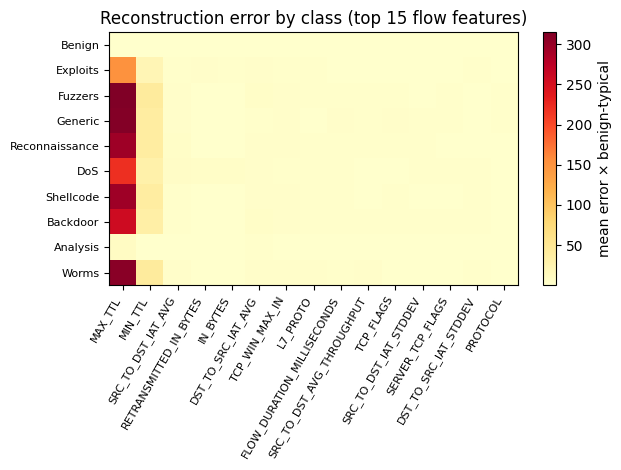

In [6]:
# === CELL 7: GLOBAL FORENSICS — where the error lives, per class ===
import collections
p99b = np.percentile(ERR_Z[test_y == 0], 99, axis=0) + 1e-8
ERRN = ERR_Z / p99b
FLOW = slice(48, 93)
BLOCKS = ['src-context (GNN)', 'flow features (45)', 'dst-context (GNN)']
BLOCK_SL = (slice(0,48), slice(48,93), slice(93,141))

classes = [c for c, _ in collections.Counter(test_cls).most_common()]
M = np.stack([ERRN[test_cls == c][:, FLOW].mean(0) for c in classes])
top15 = np.argsort(M.max(0))[::-1][:15]
Bm = np.stack([[ERR_Z[test_cls == c][:, sl].mean(0).sum() for sl in BLOCK_SL] for c in classes])
Bfrac = Bm / Bm.sum(1, keepdims=True)
TOP_FEATS = {c: [FEATURE_COLS[i] for i in np.argsort(Mk)[::-1][:5]] for c, Mk in zip(classes, M)}

exp_m = test_cls == 'Exploits'
fn_e, tp_e = exp_m & (SCORE <= THRESHOLD), exp_m & (SCORE > THRESHOLD)
gap = ERRN[tp_e][:, FLOW].mean(0) - ERRN[fn_e][:, FLOW].mean(0)
missed_feats = [FEATURE_COLS[i] for i in np.argsort(gap)[::-1][:5]]
fp_m = (test_y == 0) & (SCORE > THRESHOLD)
fp_prof = ERRN[fp_m][:, FLOW].mean(0)
fp_feats = [FEATURE_COLS[i] for i in np.argsort(fp_prof)[::-1][:5]]

print(f'Benign mean score {SCORE[test_y==0].mean():.1f} | Exploit TP {int(tp_e.sum()):,} vs FN {int(fn_e.sum()):,}')
print(f'Exploit misses lack signal in : {", ".join(missed_feats)}')
print(f'False positives driven by   : {", ".join(fp_feats)}')
for c, fr in zip(classes, Bfrac): print(f'{c:15s} error split: src {fr[0]:.0%} | flow {fr[1]:.0%} | dst {fr[2]:.0%}')

im = plt.imshow(M[:, top15], aspect='auto', cmap='YlOrRd')
plt.xticks(range(15), [FEATURE_COLS[i] for i in top15], rotation=60, ha='right', fontsize=8)
plt.yticks(range(len(classes)), classes, fontsize=8); plt.colorbar(im, label='mean error × benign-typical')
plt.title('Reconstruction error by class (top 15 flow features)'); plt.tight_layout(); plt.show()

In [7]:
# === CELL 8: SAMPLE SELECTION — 64 per group, FNs biased toward Exploits ===
rng = np.random.default_rng(SEED)
def take(mask, k, prefer=None):
    idx = np.flatnonzero(mask)
    if prefer is not None:
        p = np.flatnonzero(mask & prefer)
        if len(p) >= k // 2:
            rest = idx[~np.isin(idx, p)]
            idx = np.concatenate([rng.choice(p, k//2, replace=False),
                                  rng.choice(rest, k - k//2, replace=False)])
    return rng.choice(idx, size=min(k, len(idx)), replace=False)

G = {'TP': (test_y==1)&(SCORE>THRESHOLD), 'FP': (test_y==0)&(SCORE>THRESHOLD),
     'FN': (test_y==1)&(SCORE<=THRESHOLD), 'TN': (test_y==0)&(SCORE<=THRESHOLD)}
SAMPLES = {g: take(m, 64, prefer=(test_cls=='Exploits') if g=='FN' else None) for g, m in G.items()}
print({g: len(v) for g, v in SAMPLES.items()}, '| total deep-dives:', sum(len(v) for v in SAMPLES.values()))

{'TP': 64, 'FP': 64, 'FN': 64, 'TN': 64} | total deep-dives: 256


In [8]:
# === CELL 9: INTEGRATED GRADIENTS — attribute each edge's score to its 45 flow features ===
# The score of edge k = squared recon error of its z vector. h_src/h_dst depend only on node
# profiles, so varying the 45 flow features with the window frozen is the EXACT scoring function.
for p_ in model.parameters(): p_.requires_grad_(False)

def get_window(k):
    w0 = (k // W) * W
    return torch.from_numpy(Z[w0:w0+W]), k - w0       # (512, 141) cpu, center position

def score_from_features(x, z_win, ci):
    B = x.size(0)
    z = z_win.unsqueeze(0).expand(B, -1, -1).clone()
    z[:, ci, 48:93] = x
    zh = model.ae(z)
    return ((zh[:, ci, :] - z[:, ci, :]) ** 2).sum(-1)

def explain_edge(k, n_steps=32):
    z_win, ci = get_window(k)
    z_win = z_win.to(device)
    e0 = z_win[ci, 48:93]
    ig = IntegratedGradients(lambda x: score_from_features(x, z_win, ci))
    a = ig.attribute(e0.unsqueeze(0), baselines=torch.zeros_like(e0).unsqueeze(0),
                     n_steps=n_steps, internal_batch_size=16)
    return a.squeeze(0).cpu().numpy()

ATTR = {}
t0 = time.time()
for g, idxs in SAMPLES.items():
    for k in idxs:
        k = int(k)
        a = explain_edge(k)
        ATTR[k] = dict(group=g, ig=[(FEATURE_COLS[i], float(a[i]), float(ERRN[k, 48+i]))
                                    for i in np.argsort(np.abs(a))[::-1][:5]])
print(f'IG done: {len(ATTR)} edges in {time.time()-t0:.0f}s')
json.dump(ATTR, open('artifacts/explain_samples.json','w'), indent=2, default=str)

IG done: 256 edges in 10s


In [9]:
# === CELL 10: THREE FLAGSHIP CASE STUDIES — STYLED (console + markdown) ===
def case_block(k):
    tot = ERR_Z[k].sum()
    split = {b: round(float(ERR_Z[k, sl].sum() / tot), 3) for b, sl in zip(BLOCKS, BLOCK_SL)}
    i = int(np.argmax(ERRN[k, FLOW]))
    return dict(group=ATTR[k]['group'], true_label=str(test_cls[k]),
                src=node_names[src[test_idx[k]]], dst=node_names[dst[test_idx[k]]],
                score=round(float(SCORE[k]), 1), threshold=round(THRESHOLD, 1),
                top_flow_feature=FEATURE_COLS[i], top_ratio=round(float(ERRN[k, 48+i]), 1),
                error_split=split,
                ig_top=[dict(feature=f, attribution=round(g, 3), error_ratio=round(r, 1))
                        for f, g, r in ATTR[k]['ig']])

CASES = {g: case_block(int(SAMPLES[g][int(np.argmax(SCORE[SAMPLES[g]]))])) for g in ('TP', 'FN', 'FP')}

META = {'TP': ('✅', 'TRUE POSITIVE — correctly flagged'),
        'FN': ('🕳️', 'FALSE NEGATIVE — missed attack'),
        'FP': ('⚠️', 'FALSE POSITIVE — false alarm')}

def split_bars(split, width=24):
    short = {'src-context (GNN)': 'src-context', 'flow features (45)': 'flow features',
             'dst-context (GNN)': 'dst-context'}
    lines = []
    for b, f in split.items():
        n = max(1, int(round(f * width))) if f > 0.005 else 0
        lines.append(f"     {short[b]:<13} {'█' * n}{'░' * (width - n)} {f:6.1%}")
    return lines

def verdict(g, c):
    if g == 'TP':
        return (f"detector right for the right reason — {c['top_flow_feature']} dominates the "
                f"attribution ({c['top_ratio']}× benign-typical), the classic off-subnet TTL signature")
    if g == 'FN':
        d = round(c['threshold'] - c['score'], 1)
        return (f"anomaly is real but sub-threshold — {d} points short ({c['score']/c['threshold']:.0%} of the "
                f"cutoff); signal lives in {c['ig_top'][0]['feature']}, not the TTL channel that flags other Exploits")
    return (f"benign flow whose {c['top_flow_feature']} rhythm mimics attack patterns — "
            f"the FP cluster Phase 4 flags for threshold/whitelist tuning")

# ---------- console ----------
print('🔬 FLAGSHIP CASE STUDIES — highest-scoring TP / FN / FP in the test set')
print(f'   threshold {THRESHOLD:.1f} · scores are reconstruction error in GNN embedding space')
for g in ('TP', 'FN', 'FP'):
    c = CASES[g]
    icon, title = META[g]
    print(f"\n{'─'*74}")
    print(f"{icon} {g} · {title} · {c['true_label']}")
    print(f"{'─'*74}")
    print(f"   {c['src']} → {c['dst']}")
    print(f"   score {c['score']} vs threshold {c['threshold']}"
          + (f"  ({c['score']/c['threshold']:.1f}× over)" if g != 'FN'
             else f"  ({c['score']/c['threshold']:.0%} of cutoff)"))
    print(f"   strongest anomaly: {c['top_flow_feature']} ({c['top_ratio']}× benign-typical)")
    print('   where the error lives:')
    print('\n'.join(split_bars(c['error_split'])))
    print('   Integrated Gradients (top 3):')
    for j, d in enumerate(c['ig_top'][:3], 1):
        print(f"     {j}. {d['feature']:<26} {d['attribution']:+9.3f}   ({d['error_ratio']}× err)")
    print(f"   ▸ verdict: {verdict(g, c)}")

# ---------- markdown artifact for the README/report ----------
md = ['# 🔬 GraphIDS — Flagship Case Studies', '',
      f'> highest-scoring TP / FN / FP in the test set · threshold **{THRESHOLD:.1f}** · '
      'scores are reconstruction error in GNN embedding space', '']
for g in ('TP', 'FN', 'FP'):
    c = CASES[g]
    icon, title = META[g]
    md += [f"## {icon} {g} · {title} · `{c['true_label']}`", '',
           f"> **`{c['src']}` → `{c['dst']}`** · score **{c['score']}** vs threshold **{c['threshold']}**"
           + (f" ({c['score']/c['threshold']:.1f}× over)" if g != 'FN'
              else f" ({c['score']/c['threshold']:.0%} of cutoff)"), '',
           f"**Strongest anomaly:** `{c['top_flow_feature']}` at **{c['top_ratio']}×** benign-typical error", '',
           '| where the error lives | share |', '|---|---:|']
    for b, v in c['error_split'].items():
        md.append(f"| {b} | {v:.1%} |")
    md += ['', '**Integrated Gradients (top 3):**', '',
           '| # | feature | IG attribution | error × benign |', '|---|---|---:|---:|']
    for j, d in enumerate(c['ig_top'][:3], 1):
        md.append(f"| {j} | `{d['feature']}` | {d['attribution']:+.3f} | {d['error_ratio']}× |")
    md += ['', f"**Verdict:** {verdict(g, c)}", '', '---', '']
open('artifacts/phase4_cases.md', 'w').write('\n'.join(md))
print('\nSaved: artifacts/phase4_cases.md')

🔬 FLAGSHIP CASE STUDIES — highest-scoring TP / FN / FP in the test set
   threshold 126.7 · scores are reconstruction error in GNN embedding space

──────────────────────────────────────────────────────────────────────────
✅ TP · TRUE POSITIVE — correctly flagged · Exploits
──────────────────────────────────────────────────────────────────────────
   175.45.176.2 → 149.171.126.16
   score 379.8 vs threshold 126.7  (3.0× over)
   strongest anomaly: MAX_TTL (358.5× benign-typical)
   where the error lives:
     src-context   █░░░░░░░░░░░░░░░░░░░░░░░   2.5%
     flow features ███████████████████████░  95.4%
     dst-context   █░░░░░░░░░░░░░░░░░░░░░░░   2.1%
   Integrated Gradients (top 3):
     1. MAX_TTL                     +159.756   (358.5× err)
     2. MIN_TTL                     +104.133   (44.5× err)
     3. SHORTEST_FLOW_PKT            +91.712   (15.2× err)
   ▸ verdict: detector right for the right reason — MAX_TTL dominates the attribution (358.5× benign-typical), the classic off

In [10]:
# === CELL 11: LLM ALERTS — DECISION LOGIC FIRST, THEN PLAIN-TEXT RESULT ===
# Console policy: for every edge show (1) the decision logic — rule, numbers, which branch
# fired, evidence — then (2) the LLM verdict in clean plain text (no markdown symbols).
# The .md artifact keeps its styled markdown (that renders on GitHub); the console never does.
import requests, collections

def get_groq_key():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret('GROQ_API_KEY')
    except Exception:
        return os.environ.get('GROQ_API_KEY')

LLM_MODEL      = 'openai/gpt-oss-20b'        # internal only — never written to any artifact
FALLBACK_MODEL = 'llama-3.3-70b-versatile'   # internal only — used if a call returns empty

PROMPT = """You are a senior SOC analyst writing alert narratives from a graph-based anomaly detector (GraphIDS).
Using ONLY the JSON below, write the narrative in EXACTLY this format (keep the bold labels):

**Severity:** <critical | high | medium | low> — <five-word verdict with one fitting emoji>
**What happened:** <one sentence naming source IP -> destination IP>
**Why flagged:** <2-3 features BY NAME with value and error_ratio, e.g. "MAX_TTL = 9.2, 321x benign-typical error">
**Behaviour hypothesis:** <one hedged sentence starting with "consistent with ...">
**Recommended action:** <one concrete step>

Rules: max 120 words. Values are standardized (z-score-like) — speak of relative magnitude, never invent units.
Never invent features or numbers not in the JSON. If kind is "missed", write a detection-gap analysis in the
same format but replace the Severity line with: **Detection gap:** <why the model missed it, with numbers>.

JSON:
{rec}"""

def faithfulness(text, feats):
    t = text.lower()
    return float(np.mean([any(w in t for w in re.split(r'[_ ]', f.lower()) if len(w) >= 3)
                          or f.lower() in t for f in feats]))

def make_rec(kind, k):
    top = [dict(feature=f, value=round(float(edge_attr[test_idx[k], FEATURE_COLS.index(f)]), 3),
                error_ratio=round(float(r), 1), attribution=round(float(g), 3)) for f, g, r in ATTR[k]['ig']]
    rec = dict(kind=kind, score=round(float(SCORE[k]), 1), threshold=round(THRESHOLD, 1),
               src=node_names[src[test_idx[k]]], dst=node_names[dst[test_idx[k]]], top_features=top)
    if kind == 'missed':
        rec['true_label'] = str(test_cls[k]); rec['distance_to_threshold'] = round(THRESHOLD - float(SCORE[k]), 1)
    return rec

key = get_groq_key()
def groq_call(rec, model):
    base = {'model': model, 'temperature': 0.2, 'max_tokens': 1000,
            'messages': [{'role': 'user', 'content': PROMPT.format(rec=json.dumps(rec))}]}
    for payload in [dict(base, reasoning_effort='low'), base]:
        for _ in range(2):
            try:
                r = requests.post('https://api.groq.com/openai/v1/chat/completions',
                                  headers={'Authorization': f'Bearer {key}'}, json=payload, timeout=90)
                r.raise_for_status()
                txt = (r.json()['choices'][0]['message'].get('content') or '').strip()
                if txt: return txt
            except Exception:
                pass
            time.sleep(2)
    return ''

def groq_alert(rec):
    txt = groq_call(rec, LLM_MODEL)
    return txt if txt else groq_call(rec, FALLBACK_MODEL)

SEV_ICON = {'critical': '🔴', 'high': '🟠', 'medium': '🟡', 'low': '🟢', 'gap': '🕳️'}

def sev_of(txt, kind):
    if kind == 'missed': return 'gap'
    m = re.search(r'severity[:\s]*\**\s*([a-z]+)', txt.lower())
    w = m.group(1) if m else 'high'
    return w if w in SEV_ICON else 'high'

jobs = [('alert', int(k)) for k in SAMPLES['TP'][:15]] + [('alert', int(k)) for k in SAMPLES['FP'][:15]] \
     + [('missed', int(k)) for k in SAMPLES['FN'][:6]]
ALERTS, FAITHS, fails = [], [], 0
for kind, k in jobs:
    rec = make_rec(kind, k)
    txt = '' if not key else groq_alert(rec)
    if not txt: fails += 1
    else: FAITHS.append(faithfulness(txt, [f for f, _, _ in ATTR[k]['ig']]))
    ALERTS.append(dict(kind=kind, pos=k, true_label=str(test_cls[k]), severity=sev_of(txt, kind),
                       record=rec, narration=txt))
    time.sleep(1.2)

FAITH = float(np.mean(FAITHS)) if FAITHS else 0.0

# ---------- STYLED MARKDOWN REPORT (file artifact — renders on GitHub) ----------
sev_counts = collections.Counter(a['severity'] for a in ALERTS)
md = ['# 🛡️ GraphIDS — SOC Alert Narratives', '',
      f'> **{len(ALERTS)}** narrations · faithfulness **{FAITH:.0%}** · threshold **{THRESHOLD:.1f}**', '',
      '## 📊 Dashboard', '',
      '| # | Type | Label | Flow | Score | Severity |',
      '|---|------|-------|------|------:|----------|']
for i, a in enumerate(ALERTS, 1):
    r = a['record']
    typ = '🚨 alert' if a['kind'] == 'alert' else '🕳️ missed'
    sev = f"{SEV_ICON[a['severity']]} {a['severity']}" if a['kind'] == 'alert' else '🕳️ gap'
    md.append(f"| {i:02d} | {typ} | {a['true_label']} | `{r['src']}` → `{r['dst']}` | {r['score']} | {sev} |")
md += ['', '---', '']
for i, a in enumerate(ALERTS, 1):
    r = a['record']
    icon  = '🚨' if a['kind'] == 'alert' else '🕳️'
    badge = f"{SEV_ICON[a['severity']]} **{a['severity'].upper()}**" if a['kind'] == 'alert' else '🕳️ **DETECTION GAP**'
    md.append(f"## {icon} {i:02d} · {badge} · `{a['true_label']}`")
    md.append('')
    md.append(f"> **{r['src']} → {r['dst']}** · score **{r['score']}** vs threshold **{r['threshold']}**"
              + (f" · gap **{r['distance_to_threshold']}**" if 'distance_to_threshold' in r else ''))
    md.append('')
    md.append(a['narration'])
    md.append('')
    md.append('| feature | value (z) | error × benign | IG attribution |')
    md.append('|--------:|----------:|---------------:|---------------:|')
    for f in r['top_features']:
        md.append(f"| `{f['feature']}` | {f['value']} | {f['error_ratio']}× | {f['attribution']:+.3f} |")
    md += ['', '---', '']
md.append(f'*Generated {time.strftime("%Y-%m-%d %H:%M")} · GraphIDS Phase 4 explainability pipeline*')
open('artifacts/phase4_narration.md', 'w').write('\n'.join(md))
json.dump(ALERTS, open('artifacts/phase4_alerts.json', 'w'), indent=2, default=str)

# ---------- CONSOLE: overview table, then per-edge decision logic + plain-text result ----------
def plain(t):
    """Strip every markdown symbol so the console shows clean plain text."""
    t = re.sub(r'\*+', '', t)
    t = t.replace('`', '')
    t = re.sub(r'^#{1,6}\s*', '', t, flags=re.M)
    return t.strip()

print(f'🛡️  SOC report — {len(ALERTS)} narrations ({fails} failed) | faithfulness {FAITH:.0%}')
print('   severity mix: ' + ' | '.join(f'{SEV_ICON[s]} {n}' for s, n in sev_counts.most_common()))
print('\n   OVERVIEW (all edges, decision at a glance)')
for i, a in enumerate(ALERTS, 1):
    r = a['record']
    tag = '🚨' if a['kind'] == 'alert' else '🕳️'
    sev = SEV_ICON[a['severity']] if a['kind'] == 'alert' else '🕳️'
    call = 'FLAG' if a['kind'] == 'alert' else 'pass'
    print(f"   {i:02d} {tag} {a['true_label']:<15} {r['src']} → {r['dst']}  score {r['score']:>7} vs {r['threshold']} → {call} {sev}")

def console_block(i, a):
    r = a['record']
    out = ['─' * 74]
    if a['kind'] == 'alert':
        out.append(f"🚨 ALERT {i:02d} · {a['true_label']} · {SEV_ICON[a['severity']]}")
    else:
        out.append(f"🕳️ MISSED {i:02d} · {a['true_label']} · detection gap")
    out.append('─' * 74)
    out.append('  DECISION LOGIC')
    out.append(f"  rule    : IF score > threshold {r['threshold']} → FLAG as anomaly, ELSE → pass")
    out.append(f"  edge    : {r['src']} → {r['dst']}")
    if a['kind'] == 'alert':
        out.append(f"  check   : {r['score']} > {r['threshold']}  →  FLAG ✅  ({r['score']/r['threshold']:.1f}× over threshold)")
        if a['true_label'] == 'Benign':
            out.append('  outcome : true label = Benign  →  FALSE ALARM (false positive)')
        else:
            out.append(f"  outcome : true label = {a['true_label']}  →  CORRECT DETECTION (true positive)")
    else:
        out.append(f"  check   : {r['score']} ≤ {r['threshold']}  →  PASS ❌  ({r['distance_to_threshold']} below threshold)")
        out.append(f"  outcome : true label = {a['true_label']}  →  MISSED ATTACK (false negative)")
    out.append('  evidence (top features by IG attribution):')
    for f in r['top_features']:
        out.append(f"    {f['feature']:<26} value {f['value']:>7}   error {f['error_ratio']:>7}×   IG {f['attribution']:+9.3f}")
    out.append('')
    out.append('  RESULT — LLM SOC verdict')
    if not a['narration']:
        out.append('    (no narration — LLM call failed)')
        return '\n'.join(out)
    for ln in plain(a['narration']).splitlines():
        ln = ln.strip()
        if not ln: continue
        m = re.match(r'^([A-Za-z][A-Za-z ]+?):\s*(.*)$', ln)
        out.append(f"    {m.group(1):<20}: {m.group(2)}" if m else f"    {ln}")
    return '\n'.join(out)

for i, a in enumerate(ALERTS, 1):
    print(); print(console_block(i, a))
print('\nSaved: artifacts/phase4_narration.md · artifacts/phase4_alerts.json')

🛡️  SOC report — 36 narrations (0 failed) | faithfulness 84%
   severity mix: 🟠 29 | 🕳️ 6 | 🔴 1

   OVERVIEW (all edges, decision at a glance)
   01 🚨 Fuzzers         175.45.176.0 → 149.171.126.13  score   205.8 vs 126.7 → FLAG 🟠
   02 🚨 Fuzzers         175.45.176.3 → 149.171.126.14  score   201.2 vs 126.7 → FLAG 🟠
   03 🚨 Fuzzers         175.45.176.1 → 149.171.126.11  score   312.5 vs 126.7 → FLAG 🟠
   04 🚨 Fuzzers         175.45.176.1 → 149.171.126.15  score   232.4 vs 126.7 → FLAG 🟠
   05 🚨 Exploits        175.45.176.3 → 149.171.126.10  score   217.8 vs 126.7 → FLAG 🟠
   06 🚨 Generic         175.45.176.3 → 149.171.126.18  score   243.3 vs 126.7 → FLAG 🟠
   07 🚨 Exploits        175.45.176.1 → 149.171.126.14  score   229.1 vs 126.7 → FLAG 🟠
   08 🚨 Reconnaissance  175.45.176.2 → 149.171.126.16  score   233.2 vs 126.7 → FLAG 🟠
   09 🚨 Generic         175.45.176.1 → 149.171.126.14  score   260.8 vs 126.7 → FLAG 🟠
   10 🚨 Fuzzers         175.45.176.1 → 149.171.126.15  score   244.6 vs 12

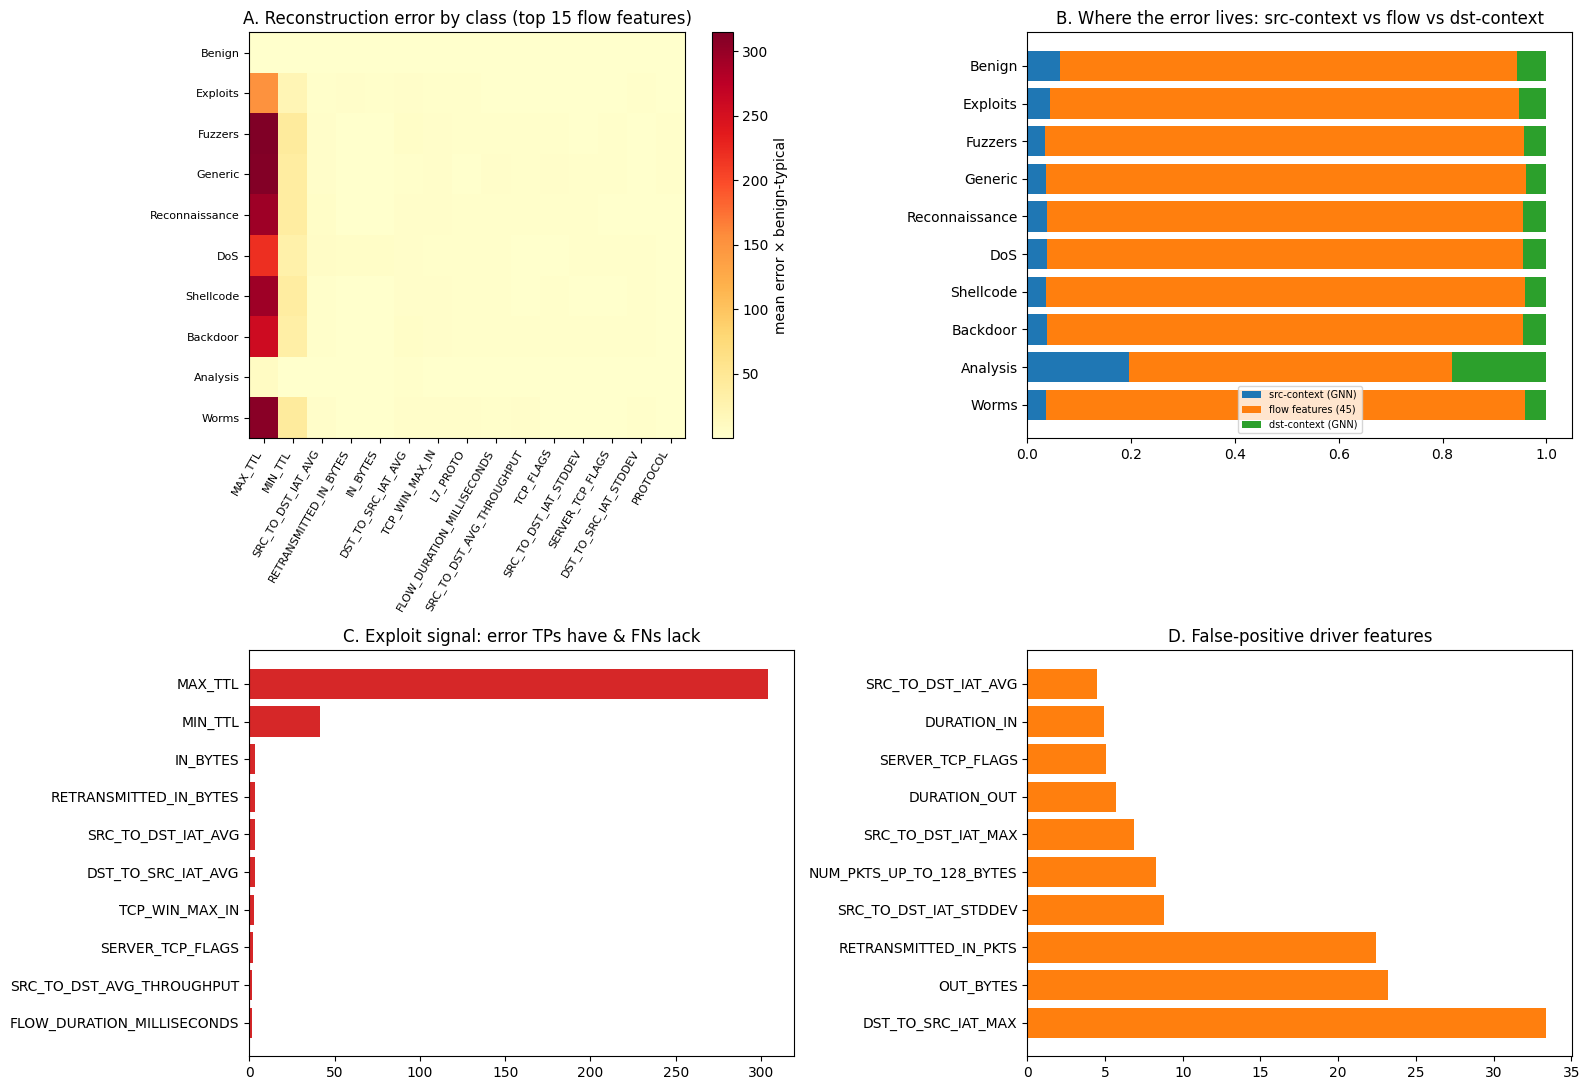

PHASE 4 GATE: ✅ PASS
Next: Save Version (with outputs) → upload 5 artifacts + notebook → update README → Phase 5.


In [11]:
# === CELL 12: FIGURES + SUMMARY + PHASE 4 GATE ===
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
im = axes[0,0].imshow(M[:, top15], aspect='auto', cmap='YlOrRd')
axes[0,0].set_xticks(range(15)); axes[0,0].set_xticklabels([FEATURE_COLS[i] for i in top15], rotation=60, ha='right', fontsize=8)
axes[0,0].set_yticks(range(len(classes))); axes[0,0].set_yticklabels(classes, fontsize=8)
plt.colorbar(im, ax=axes[0,0], label='mean error × benign-typical')
axes[0,0].set_title('A. Reconstruction error by class (top 15 flow features)')
left = np.zeros(len(classes))
for b in range(3):
    axes[0,1].barh(classes, Bfrac[:, b], left=left, label=BLOCKS[b]); left += Bfrac[:, b]
axes[0,1].invert_yaxis(); axes[0,1].legend(fontsize=7)
axes[0,1].set_title('B. Where the error lives: src-context vs flow vs dst-context')
o = np.argsort(gap)[::-1][:10]
axes[1,0].barh([FEATURE_COLS[i] for i in o][::-1], gap[o][::-1], color='tab:red')
axes[1,0].set_title('C. Exploit signal: error TPs have & FNs lack')
o = np.argsort(fp_prof)[::-1][:10]
axes[1,1].barh([FEATURE_COLS[i] for i in o][::-1], fp_prof[o], color='tab:orange')
axes[1,1].set_title('D. False-positive driver features')
plt.tight_layout(); plt.savefig('artifacts/phase4_figures.png', dpi=140); plt.show()

summary4 = dict(phase='Phase 4 — Explainability & LLM narration',
    finished=time.strftime('%Y-%m-%d %H:%M:%S'),
    reproduction_gate='PASS' if REPRO_OK else 'FAIL', note=note,
    pr_auc_reproduced=round(float(pr),4), roc_auc_reproduced=round(float(roc),4),
    z_layout='z = [src-context 48 | flow 45 | dst-context 48]',
    feature_names_source=('scaler.feature_names_in_' if hasattr(scaler, 'feature_names_in_')
                          and len(getattr(scaler, 'feature_names_in_', [])) == 45 else 'verified fingerprint ordering'),
    edges_explained=len(ATTR), narrations=len(ALERTS), narration_failures=fails,
    faithfulness=round(FAITH,3),
    exploit_missed_features=missed_feats, fp_driver_features=fp_feats,
    error_split_by_class={c: [round(float(x),3) for x in fr] for c, fr in zip(classes, Bfrac)},
    class_top_features=TOP_FEATS, case_studies=CASES)
json.dump(summary4, open('artifacts/phase4_summary.json','w'), indent=2, default=str)

checks = dict(reproduction=REPRO_OK, ig_edges=len(ATTR)>=200, narrations=len(ALERTS)-fails>=30,
              faithfulness=FAITH>=0.5, cases=len(CASES)==3)
gate = '✅ PASS' if all(checks.values()) else '⚠️ WARN — ' + str({k for k,v in checks.items() if not v})
print('PHASE 4 GATE:', gate)
print('Next: Save Version (with outputs) → upload 5 artifacts + notebook → update README → Phase 5.')